# Notebook 05: Market Segments (K-Means Clustering)
Goal: To Group Berlin Airbnb listings into market segments with similar
characteristics and compare their prices.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/listings_model.csv")
df.shape

(8075, 29)

In [12]:
cluster_features = [
    "accommodates", "bedrooms", "bathrooms", "long_stay",
    "room_type_Private room", "room_type_Shared room",
    "review_scores_rating", "host_is_superhost", "log_price"
]
data = df[cluster_features]
data.describe().round(2)

,accommodates,bedrooms,bathrooms,long_stay,room_type_Private room,room_type_Shared room,review_scores_rating,host_is_superhost,log_price
count,8075.00,8075.00,8075.00,8075.00,8075.00,8075.00,8075.00,8075.00,8075.00
mean,3.38,1.32,1.14,0.19,0.27,0.01,4.76,0.36,4.86
std,2.16,0.83,0.44,0.39,0.44,0.10,0.33,0.48,0.64
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.63
25%,2.00,1.00,1.00,0.00,0.00,0.00,4.69,0.00,4.40
50%,3.00,1.00,1.00,0.00,0.00,0.00,4.84,0.00,4.86
75%,4.00,2.00,1.00,0.00,1.00,0.00,4.93,1.00,5.30
max,16.00,8.00,8.50,1.00,1.00,1.00,5.00,1.00,6.54


In [13]:
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)
data_scaled[:3].round(2)

array([[-0.64, -0.39, -0.31, -0.48, -0.6 , -0.1 , -2.32, -0.75, -0.43],
       [-0.64, -0.39, -0.31, -0.48, -0.6 , -0.1 ,  0.25, -0.75, -0.94],
       [ 0.29,  0.82, -0.31, -0.48, -0.6 , -0.1 ,  0.74, -0.75,  0.84]])

## 1. Features and scaling
I clustered listings on 9 features that describe the type of listing (guests,
bedrooms, bathrooms, room type, long stay), its quality (review score,
superhost) and its price level (log price). District columns were left out so
that segments reflect the type of listing rather than its location; location
is compared afterwards. Because K-Means is based on distances, all features
were standardised (mean 0, standard deviation 1) so that no feature dominates
just because of its scale.

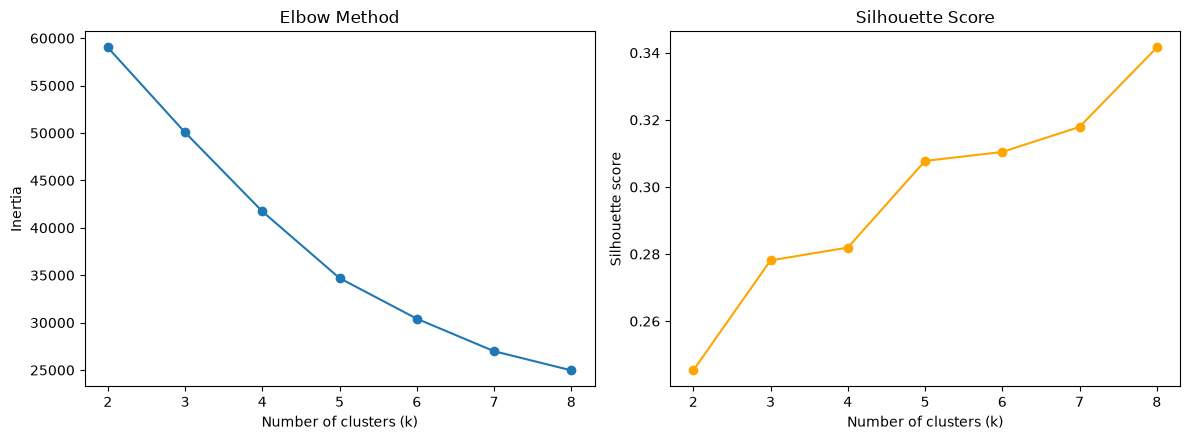

,k,silhouette
0,2,0.245
1,3,0.278
2,4,0.282
3,5,0.308
4,6,0.310
5,7,0.318
6,8,0.342


In [14]:
inertias = []
silhouettes = []
k_values = range(2, 9)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(data_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(data_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouettes, marker="o", color="orange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.savefig("../images/11_choosing_k.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"k": k_values, "silhouette": np.round(silhouettes, 3)})

## 2. Choosing the number of clusters
I tested k = 2 to 8 using the elbow method and the silhouette score. The elbow
curve has no sharp bend, but the decrease in inertia becomes smaller after
k = 5. The silhouette score shows its largest jump between k = 4 and k = 5
(0.282 to 0.308) and only rises slowly after that. Higher values at k = 7–8
are partly caused by the binary features, which allow many small, similar
groups. I chose k = 5 as a balance between separation and segments that are
few enough to describe. Silhouette scores of around 0.3 indicate moderate
separation: the market does not split into perfectly distinct groups, so the
segments should be seen as a useful simplification.

In [15]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(data_scaled)
df["cluster"].value_counts().sort_index()

cluster
0    1108
1    1834
2    1435
3      76
4    3622
Name: count, dtype: int64

In [16]:
profile = df.groupby("cluster")[cluster_features].mean().round(2)
profile["median price (€)"] = df.groupby("cluster")["price"].median().round(0)
profile["listings"] = df["cluster"].value_counts().sort_index()
profile

,accommodates,bedrooms,bathrooms,long_stay,room_type_Private room,room_type_Shared room,review_scores_rating,host_is_superhost,log_price,median price (€),listings
cluster,,,,,,,,,,,
0,7.16,2.82,1.70,0.07,0.02,0.0,4.76,0.44,5.65,294.0,1108
1,2.11,0.99,1.10,0.00,1.00,0.0,4.76,0.40,4.56,90.0,1834
2,2.52,1.16,1.08,1.00,0.20,0.0,4.79,0.11,4.18,64.0,1435
3,3.70,0.88,0.99,0.03,0.00,1.0,4.60,0.17,3.57,28.0,76
4,3.21,1.10,1.01,0.00,0.00,0.0,4.75,0.42,5.07,157.0,3622


In [17]:
names = {
    0: "Large group & family homes",
    1: "Private rooms",
    2: "Long-stay rentals",
    3: "Shared rooms / dorms",
    4: "Standard holiday apartments"
}
df["segment"] = df["cluster"].map(names)

seg = df.groupby("segment").agg(
    listings=("price", "size"),
    median_price=("price", "median")
).sort_values("median_price", ascending=False)
seg["share (%)"] = (seg["listings"] / len(df) * 100).round(1)
seg

,listings,median_price,share (%)
segment,,,
Large group & family homes,1108,294.30,13.7
Standard holiday apartments,3622,156.58,44.9
Private rooms,1834,90.00,22.7
Long-stay rentals,1435,64.44,17.8
Shared rooms / dorms,76,27.50,0.9


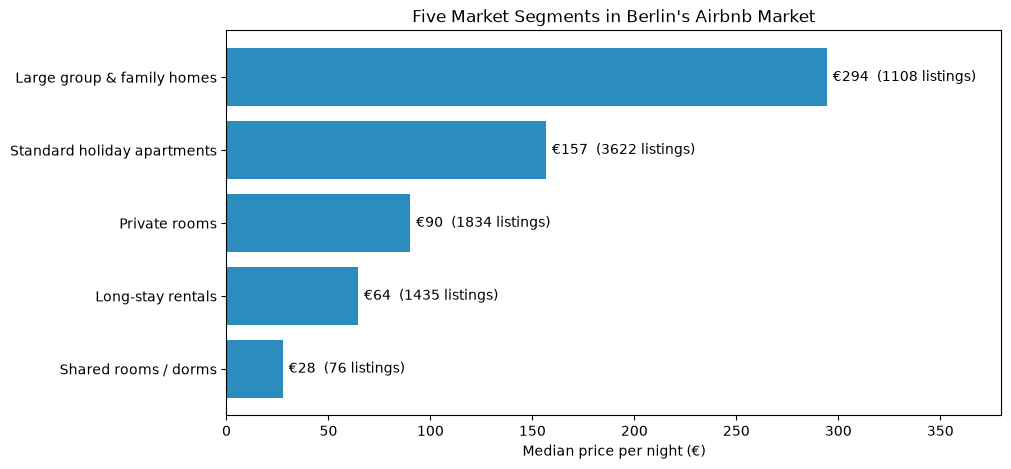

In [18]:
plt.figure(figsize=(10, 5))
bars = plt.barh(seg.index, seg["median_price"], color="#2b8cbe")
for bar, n in zip(bars, seg["listings"]):
    plt.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2,
             f"€{bar.get_width():.0f}  ({n} listings)", va="center")
plt.title("Five Market Segments in Berlin's Airbnb Market")
plt.xlabel("Median price per night (€)")
plt.gca().invert_yaxis()
plt.xlim(0, 380)
plt.savefig("../images/12_market_segments.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. The five market segments
K-Means with k = 5 produced five clearly interpretable segments:
- Large group & family homes (14%): about 7 guests and 3 bedrooms, median €294.
- Standard holiday apartments (45%): entire homes for about 3 guests, median
  €157 — the core of the market.
- Private rooms (23%): rooms in shared homes for about 2 guests, median €90.
- Long-stay rentals (18%): all require 30+ nights, median €64 — cheaper than
  private rooms even though most are entire flats. Only 11% of these hosts are
  superhosts, compared to about 40% in the other segments.
- Shared rooms / dorms (1%): the cheapest (€28) and lowest-rated (4.60).
The segments are defined by size, room type and stay length — the same drivers
found in the regression analysis, which confirms these results with a
different method.

In [19]:
clean = pd.read_csv("../data/listings_clean.csv")
df["district"] = clean["neighbourhood_group_cleansed"]

mix = pd.crosstab(df["district"], df["segment"], normalize="index") * 100
mix = mix.round(1).sort_values("Long-stay rentals", ascending=False)
mix

segment,Large group & family homes,Long-stay rentals,Private rooms,Shared rooms / dorms,Standard holiday apartments
district,,,,,
Steglitz - Zehlendorf,13.3,27.5,24.2,0.8,34.2
Reinickendorf,4.7,27.1,34.9,0.8,32.6
Marzahn - Hellersdorf,15.5,25.0,22.6,0.0,36.9
Charlottenburg-Wilm.,11.0,20.7,26.9,0.1,41.2
Mitte,17.4,18.3,19.7,1.7,42.9
Friedrichshain-Kreuzberg,11.7,18.3,21.9,1.7,46.4
Neukölln,8.8,17.6,30.8,0.8,42.0
Pankow,17.1,15.4,16.1,0.3,51.1
Treptow - Köpenick,13.8,15.2,17.6,0.0,53.5


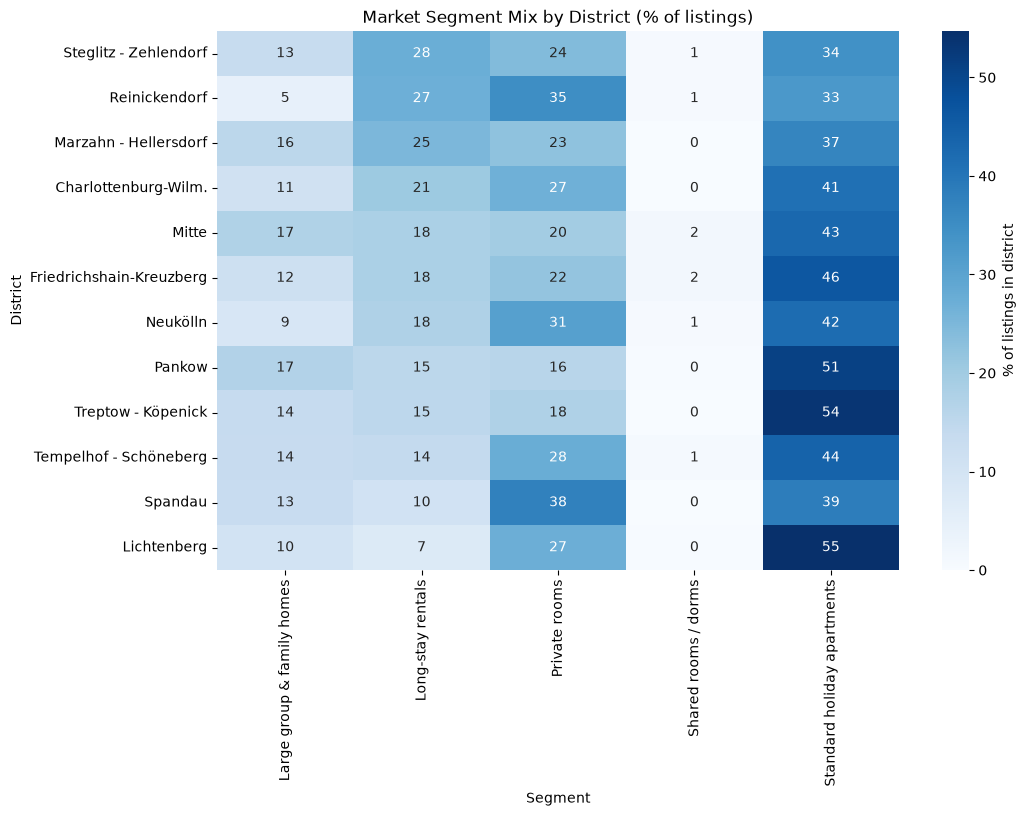

In [20]:
plt.figure(figsize=(11, 7))
sns.heatmap(mix, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of listings in district"})
plt.title("Market Segment Mix by District (% of listings)")
plt.xlabel("Segment")
plt.ylabel("District")
plt.savefig("../images/13_segments_by_district.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Segments by district
The district was not used to build the clusters, so the segment mix per
district shows how location relates to the type of listing.
- Long-stay rentals make up the largest share in outer, residential districts
  such as Steglitz-Zehlendorf (27.5%), Reinickendorf (27.1%) and
  Marzahn-Hellersdorf (25%), but only 7.3% in Lichtenberg. A possible
  explanation is that quieter residential areas attract mid-term guests rather
  than tourists; this would need further data to confirm.
- Standard holiday apartments dominate in Lichtenberg (55%),
  Treptow-Köpenick (54%) and Pankow (51%).
- Private rooms are most common in Spandau (38%) and Reinickendorf (35%).
- Shared rooms are found almost only in central Mitte and
  Friedrichshain-Kreuzberg, where hostels are concentrated.

## 5. Summary
K-Means identified five market segments defined mainly by size, room type and
minimum stay. Long-stay rentals form a distinct, low-priced segment (median
€64) that is especially common in outer residential districts. These results
support the regression findings with a different method.